# 05 — Extraction of Features from the Ministry of Commerce Records

## 1. Purpose of This Notebook

This notebook derives, from the Ministry of Commerce records alone, the features that could describe a business
idea and the market it would enter, and studies each of them on the training businesses. **No model is trained
and no feature is yet added to the model.** The results support one decision: which of these features enter the
survival model in Release 1, and which are kept for GP2.

The features answer the two sub-questions of the research question:

| Sub-question | Feature groups |
|---|---|
| RQ1: characteristics of the idea | Group 1, business-level features |
| RQ2: conditions of the market the idea would enter | Groups 2 to 6, market features (relative capital, business demography, market crowding, concentration, maturity, legal structure) |

The notebook proceeds in seven stages:

1. Time split of the labelled businesses.
2. Leakage check of the sector classification.
3. Business-level features.
4. Market table: one row per quarter and market.
5. Market features of each business.
6. Profile of each feature.
7. Correlation between the features.

**Rules applied to every feature**

1. *Point in time.* Every market statistic is taken from the latest complete quarterly record before the
   founding quarter of the business; nothing recorded after the founding is used.
2. *Available to the founder.* Every feature can be computed for a person who has not yet founded the business.
3. *No inferred presence.* Market counts use only the complete quarterly records, in which presence is observed
   and was never completed (Notebook 02, section 5.1).
4. *Missing stays missing.* A feature that cannot be computed is left missing, never set to zero.
5. *Small markets.* When a sector and region market holds fewer than 30 active businesses, its rates, medians and
   shares are taken from the sector at national level.
6. *Unclassified sector.* For a business without a sector, market statistics are taken at region level.
7. *Test data never opened.* Only the training businesses are studied; the validation and test businesses are
   counted and then set aside.

## 2. Environment Configuration

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    %pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

from mc_files import QUARTERS

warnings.simplefilter('ignore', FutureWarning)
REPORTS = SRC_DIR.parent / 'reports'
REPORTS.mkdir(exist_ok=True)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

businesses = pd.read_parquet(need(PIPE / '02_businesses.parquet', '02_preprocess_businesses'))
print(f'Businesses loaded from Notebook 02: {len(businesses):,}')

Businesses loaded from Notebook 02: 2,115,778


## 3. Stage 1 — Time Split of the Labelled Businesses

The model must predict businesses founded in the future, so the labelled businesses are split by founding
quarter: the oldest quarters are used for training, the next for validation and the most recent for the final
test. The split is fixed here, before any feature is studied:

| Set | Founding quarters | Use |
|---|---|---|
| Training | 2023 Q1 to 2024 Q4 | Studied in this notebook |
| Validation | 2025 Q1 and 2025 Q2 | Comparison of models (Notebook 06) |
| Test | 2025 Q3 | Final evaluation (Sprint 3), opened once |

Only the number of businesses in each set is shown; the outcome of the validation and test businesses is not
examined.

In [3]:
SPLIT = {'training': ('2023Q1', '2024Q4'), 'validation': ('2025Q1', '2025Q2'), 'test': ('2025Q3', '2025Q3')}
labelled = businesses[businesses['survived_first_year'].notna()]
split = pd.Series(pd.NA, index=labelled.index, dtype='string')
for name, (first, last) in SPLIT.items():
    split[labelled['founding_quarter'].between(first, last)] = name
assert split.notna().all(), 'A labelled business falls outside the split'

print(pd.DataFrame({'founding quarters': [f'{a} to {b}' if a != b else a for a, b in SPLIT.values()],
                    'businesses': split.value_counts().reindex(SPLIT.keys()),
                    'share': split.value_counts(normalize=True).reindex(SPLIT.keys()).map('{:.1%}'.format)},
                   index=list(SPLIT.keys())).to_string())

training = labelled[split == 'training'].copy()
training['failed'] = 1 - training['survived_first_year'].astype(int)
del labelled, split
print(f'\nTraining businesses studied: {len(training):,}')

           founding quarters  businesses  share
training    2023Q1 to 2024Q4      581351  65.6%
validation  2025Q1 to 2025Q2      183175  20.7%
test                  2025Q3      121976  13.8%

Training businesses studied: 581,351


**Result.** Of the 886,502 labelled businesses, 581,351 (65.6%) founded from 2023 Q1 to 2024 Q4 form the
training set, 183,175 (20.7%) founded in 2025 Q1 and 2025 Q2 form the validation set, and 121,976 (13.8%) founded
in 2025 Q3 form the test set.

**Interpretation.** Every result that follows is computed on the 581,351 training businesses only. The outcome
of the validation and test businesses is not examined in this notebook.

In [4]:
by_quarter = training.groupby('founding_quarter').agg(
    businesses=('failed', 'size'), failure_rate=('failed', 'mean'),
    check_record_complete=('check_record_complete', 'mean'))
print(by_quarter.to_string(formatters={'failure_rate': '{:.1%}'.format, 'check_record_complete': '{:.0%}'.format}))

                  businesses failure_rate check_record_complete
founding_quarter                                               
2023Q1                 49921        20.8%                  100%
2023Q2                 43845        20.5%                  100%
2023Q3                 54054        27.3%                    0%
2023Q4                 67231        20.4%                    0%
2024Q1                 74421        17.5%                    0%
2024Q2                 95716        10.2%                  100%
2024Q3                 92821        16.8%                    0%
2024Q4                103342        13.9%                  100%


**Result.** The failure rate of the training businesses is 17.3% overall. It ranges from 10.2% (2024 Q2) to
27.3% (2023 Q3). Four of the eight training quarters have an incomplete survival check record.

**Interpretation.** The failure rate differs markedly between founding quarters. 2023 Q3 is founded in an
incomplete quarter and checked in another (Notebook 02, limitation 8), and 2024 Q2 contains the wave of limited
liability companies observed in Notebook 02. A feature that changes mainly from one founding quarter to another
can therefore appear related to failure only because it identifies the quarter.

The characteristics of a business are its first recorded values (Notebook 02, Stage 3). They describe the
business at its founding only if it was recorded soon after it. The next cell measures, for each training
business, the number of quarters between its founding quarter and the first quarterly record in which it
appears, and whether that first record comes after its survival check quarter.

In [5]:
delay = (training['first_seen_quarter'].map(lambda q: pd.Period(q, 'Q').ordinal)
         - training['founding_quarter'].map(lambda q: pd.Period(q, 'Q').ordinal))
training['first_seen_after_check'] = training['first_seen_quarter'] > training['survival_check_quarter']
groups = pd.cut(delay, [-100, 0, 1, 4, 100], labels=['same quarter or earlier', '1 quarter', '2 to 4 quarters', 'more than 4 quarters'])
print('Quarters between founding and first appearance:')
print(training.groupby(groups, observed=True)['failed'].agg(businesses='size', failure_rate='mean')
      .to_string(formatters={'failure_rate': '{:.1%}'.format}))
late = training['first_seen_after_check']
print(f'\nFirst seen after the survival check quarter: {late.sum():,} businesses ({late.mean():.1%}), '
      f'failure rate {training.loc[late, "failed"].mean():.1%}')
print('Their first quarterly record:')
print(training.loc[late, 'first_seen_quarter'].value_counts().sort_index().to_string())

Quarters between founding and first appearance:
                         businesses failure_rate
same quarter or earlier      432575        14.0%
1 quarter                     69828        17.9%
2 to 4 quarters               58179        11.6%
more than 4 quarters          20769       100.0%

First seen after the survival check quarter: 20,769 businesses (3.6%), failure rate 100.0%
Their first quarterly record:
first_seen_quarter
2025Q1     499
2025Q2    6934
2025Q4    4820
2026Q1    5680
2026Q2    1237
2026Q3    1599


**Result.** 432,575 training businesses (74.4%) appear in the record of their founding quarter, and 69,828
(12.0%) one quarter later. 20,769 businesses (3.6%) appear for the first time more than four quarters after
their founding, that is, after their survival check quarter: 499 in 2025 Q1, 6,934 in 2025 Q2 and 13,336 from
2025 Q4 onwards. All of them are labelled failed (100.0%).

**Interpretation.** These 20,769 businesses are labelled failed because they are absent at their survival
check, yet they are present in later records, and their characteristics are recorded after the outcome. Both
their label and their characteristics are therefore doubtful. The records do not show why they appear so late;
a change of registration number is one possible cause, which the records do not confirm. They are retained in
this notebook and reported as an open question for Notebook 02.

## 4. Stage 2 — Leakage Check of the Sector Classification

The sector is inferred from the business name (Notebook 02, Stage 5). If the share of businesses without a sector
differed markedly between failed and surviving businesses, the classification itself would carry information
about the outcome. This check is therefore made before any feature is studied.

In [6]:
training['sector_unknown'] = training['sector'] == 'unclassified'
check = training.groupby('founding_quarter').apply(
    lambda g: pd.Series({'unclassified (survived)': g.loc[g['failed'] == 0, 'sector_unknown'].mean(),
                         'unclassified (failed)': g.loc[g['failed'] == 1, 'sector_unknown'].mean()}))
check['difference (points)'] = (check['unclassified (failed)'] - check['unclassified (survived)']) * 100
overall = training.groupby('failed')['sector_unknown'].mean()
print(check.to_string(formatters={'unclassified (survived)': '{:.1%}'.format, 'unclassified (failed)': '{:.1%}'.format,
                                  'difference (points)': '{:+.1f}'.format}))
print(f'\nAll training businesses: unclassified {overall[0]:.1%} of survived, {overall[1]:.1%} of failed '
      f'(difference {(overall[1] - overall[0]) * 100:+.1f} points)')
within = training[training['legal_form'].isin(['مؤسسة فردية', 'الشركة ذات المسؤولية المحدودة'])]
within = within.groupby([within['legal_form'].astype('string'), 'failed'])['sector_unknown'].mean().unstack()
within.columns = ['unclassified (survived)', 'unclassified (failed)']
within['difference (points)'] = (within['unclassified (failed)'] - within['unclassified (survived)']) * 100
print('\nWithin the two main legal forms:')
print(within.to_string(formatters={'unclassified (survived)': '{:.1%}'.format, 'unclassified (failed)': '{:.1%}'.format,
                                   'difference (points)': '{:+.1f}'.format}))

                 unclassified (survived) unclassified (failed) difference (points)
founding_quarter                                                                  
2023Q1                             25.4%                 29.0%                +3.6
2023Q2                             26.3%                 29.4%                +3.1
2023Q3                             26.5%                 30.3%                +3.8
2023Q4                             26.7%                 30.6%                +3.8
2024Q1                             27.7%                 32.8%                +5.1
2024Q2                             26.2%                 34.3%                +8.1
2024Q3                             29.0%                 31.6%                +2.5
2024Q4                             29.9%                 35.8%                +5.9

All training businesses: unclassified 27.5% of survived, 31.8% of failed (difference +4.3 points)



Within the two main legal forms:
                              unclassified (survived) unclassified (failed) difference (points)
legal_form                                                                                     
الشركة ذات المسؤولية المحدودة                   26.0%                 32.5%                +6.5
مؤسسة فردية                                     28.2%                 31.7%                +3.5


**Result.** 31.8% of the failed training businesses have no sector, against 27.5% of the surviving ones, a
difference of 4.3 points. The difference appears in every founding quarter (from +2.5 to +8.1 points) and within
each of the two main legal forms: +3.5 points for sole proprietorships and +6.5 points for limited liability
companies.

**Interpretation.** Businesses without a sector fail somewhat more often. The sector is inferred from the name,
which is known at the founding, so this is not information from after the founding; it indicates that names
without an activity word belong to businesses that fail more. The difference is moderate. The businesses without
a sector are therefore kept as their own category, `unclassified`, and their failure rate (19.5%) is reported
beside the others.

## 5. Stage 3 — Business-Level Features (Group 1, RQ1)

These features describe the business idea and are entered by the founder in Darb.

| Feature | Measurement | Origin |
|---|---|---|
| `economic_sector` | ISIC section (A to U) inferred from the name, or `unclassified` | Notebook 02, Stage 5 |
| `region` | One of the 13 administrative regions | Record |
| `city_group` | City with at least 1,000 training businesses, otherwise `other` | Record |
| `legal_form` | One of the 8 standardized legal entity categories | Record; Companies Law, Article 4 |
| `log_capital` | ln(1 + registered capital) for a positive capital, otherwise missing | Statistical transformation of a skewed value |
| `capital_missing` | 1 when the capital is missing, zero or negative | Record flag |
| `ecommerce` | `disclosed`, `not disclosed` or `unavailable` | Record; the attribute is absent from 2025 Q4 |
| `founding_quarter_of_year` | Q1 to Q4 | Seasonality of the founding (Geroski, Mata and Portugal, 2010) |

Registered capital stands for the capital planned by the founder. The failure rate of each category is shown
for the training businesses.

In [7]:
capital = training['registered_capital_sar'].where(training['registered_capital_flag'] == 'valid')
city_counts = training['city'].astype('string').value_counts()
LARGE_CITIES = set(city_counts[city_counts >= 1000].index)

features = pd.DataFrame(index=training.index)
features['economic_sector'] = training['sector'].astype('string')
features['region'] = training['region'].astype('string')
features['city_group'] = training['city'].astype('string').where(training['city'].astype('string').isin(LARGE_CITIES), 'other')
features['legal_form'] = training['legal_form'].astype('string')
features['log_capital'] = np.log1p(capital)
features['capital_missing'] = (training['registered_capital_flag'] != 'valid').astype(int)
features['ecommerce'] = training['ecommerce_disclosed'].map({1: 'disclosed', 0: 'not disclosed'}).astype('string').fillna('unavailable')
features['founding_quarter_of_year'] = 'Q' + training['founding_quarter'].str[-1]
CATEGORICAL = ['economic_sector', 'region', 'city_group', 'legal_form', 'ecommerce', 'founding_quarter_of_year']

print(f'Cities kept by name: {len(LARGE_CITIES)} of {training["city"].nunique()} '
      f'({features["city_group"].ne("other").mean():.1%} of training businesses)')
print(f'Capital missing, zero or negative: {features["capital_missing"].mean():.2%} of training businesses')


def rate_table(column, top=None):
    table = (pd.DataFrame({'value': features[column], 'failed': training['failed']})
             .groupby('value').agg(businesses=('failed', 'size'), failure_rate=('failed', 'mean'))
             .sort_values('businesses', ascending=False))
    table['share'] = table['businesses'] / table['businesses'].sum()
    return table[['businesses', 'share', 'failure_rate']].head(top) if top else table[['businesses', 'share', 'failure_rate']]


FORMAT = {'share': '{:.1%}'.format, 'failure_rate': '{:.1%}'.format}
print(f'\nFailure rate of all training businesses: {training["failed"].mean():.1%}')
for column in ['legal_form', 'ecommerce', 'founding_quarter_of_year', 'economic_sector']:
    print(f'\n{column}')
    print(rate_table(column).to_string(formatters=FORMAT))

Cities kept by name: 44 of 233 (93.4% of training businesses)
Capital missing, zero or negative: 0.06% of training businesses

Failure rate of all training businesses: 17.3%

legal_form


                               businesses share failure_rate
value                                                       
مؤسسة فردية                        410540 70.6%        21.1%
الشركة ذات المسؤولية المحدودة      168325 29.0%         8.2%
فرع شركة أجنبية                      1124  0.2%         1.1%
شركة المساهمة المبسطة                 496  0.1%         4.6%
شركة التضامن                          414  0.1%        10.6%
شركة المساهمة                         254  0.0%         4.3%
شركة التوصية البسيطة                  187  0.0%         0.0%
غير محدد                               11  0.0%         0.0%

ecommerce
               businesses share failure_rate
value                                       
not disclosed      542861 93.4%        15.0%
disclosed           23202  4.0%        25.6%
unavailable         15288  2.6%        87.2%

founding_quarter_of_year
       businesses share failure_rate
value                               
Q4         170573 29.3%        16.5%
Q3         146875

**Result.** 44 of the 233 cities hold at least 1,000 training businesses and cover 93.4% of them. Capital is
missing, zero or negative for 0.06%. Sole proprietorships (70.6% of the training businesses) fail at 21.1% and
limited liability companies (29.0%) at 8.2%; the other forms together hold less than 0.5%. Businesses that
disclosed e-commerce fail at 25.6% and those that did not at 15.0%; the 15,288 businesses with e-commerce
`unavailable` fail at 87.2%. By quarter of the year, the failure rate ranges from 13.4% (Q2) to 20.7% (Q3). By
sector, it ranges from 8.2% (K, finance) and 13.3% (F, construction, the largest sector with 27.7%) to 21.0% (G,
trade) and 20.7% (I, accommodation and food); unclassified businesses fail at 19.5%.

**Interpretation.** Legal form shows the largest difference among the business-level features. The e-commerce
value `unavailable` is not a characteristic of the business: the attribute is absent from the records from 2025
Q4 onwards, so it is `unavailable` exactly for businesses first recorded from that quarter, most of which are the
businesses first seen after their survival check (section 3). It must not enter a model in this form. The
quarter of the year mixes seasonality with the differences between founding quarters: Q2 contains 2024 Q2
(10.2%) and Q3 contains 2023 Q3 (27.3%).

In [8]:
for column, top in [('region', None), ('city_group', 15)]:
    print(f'\n{column}' + (f' (the {top} largest)' if top else ''))
    print(rate_table(column, top).to_string(formatters=FORMAT))
print('\nlog_capital by legal form (training businesses with a positive capital)')
print(pd.DataFrame({'legal_form': features['legal_form'], 'capital': capital})
      .groupby('legal_form')['capital'].describe(percentiles=[0.1, 0.5, 0.9])[['count', '10%', '50%', '90%']]
      .sort_values('count', ascending=False).to_string(float_format='{:,.0f}'.format))


region
                 businesses share failure_rate
value                                         
الرياض               221688 38.1%        15.1%
مكة المكرمة          110390 19.0%        18.8%
الشرقية               89679 15.4%        15.3%
القصيم                28386  4.9%        19.1%
المدينة المنورة       28366  4.9%        19.9%
عسير                  27430  4.7%        22.0%
جازان                 18424  3.2%        19.9%
نجران                 14995  2.6%        23.2%
حائل                  14415  2.5%        18.9%
تبوك                  12988  2.2%        20.3%
الجوف                  6098  1.0%        22.3%
الحدود الشمالية        5196  0.9%        19.3%
الباحة                 3296  0.6%        22.1%

city_group (the 15 largest)
                 businesses share failure_rate
value                                         
الرياض               202294 34.8%        14.7%
جده                   61894 10.6%        18.9%
other                 38224  6.6%        19.7%
مكه المكرمه           2

                                count     10%       50%         90%
legal_form                                                         
مؤسسة فردية                   410,540   5,000     5,000      10,000
الشركة ذات المسؤولية المحدودة 168,004   5,000     5,000     100,000
فرع شركة أجنبية                 1,121  10,000   100,000   1,000,000
شركة المساهمة المبسطة             496   2,000    25,000     511,445
شركة التضامن                      412   5,000     5,000     100,000
شركة المساهمة                     252 125,000 1,000,000 220,610,000
شركة التوصية البسيطة              187   5,000     5,000      31,000
غير محدد                            6       1     5,050      65,000


**Result.** By region, the failure rate ranges from 15.1% (Riyadh, 38.1% of the businesses) to 23.2% (Najran).
By city, it ranges from 7.9% (Al Jubail) and 14.7% (Riyadh) to 23.2% (Najran); the businesses of the smaller
cities grouped as `other` fail at 19.7%. The median registered capital is 5,000 SAR for sole proprietorships and
for limited liability companies; the 90th percentile is 10,000 SAR for sole proprietorships and 100,000 SAR for
limited liability companies. Joint stock companies have a median of 1,000,000 SAR.

**Interpretation.** The geographic differences are real but smaller than those of legal form. Most businesses of
both main legal forms register the same capital of 5,000 SAR, so registered capital distinguishes few businesses;
it describes the registration rather than the planned investment of the founder.

## 6. Stage 4 — Market Table

A market is a sector in a region. For each complete quarterly record, the businesses present in it are counted
and described, at four levels: sector and region, sector, region, and legal form. Only the ten complete quarterly
records are used. In them, the presence saved by Notebook 02 is the observed presence, since completion changes
the five incomplete quarters only; the first cell confirms this against the counts observed in Notebook 02
(section 8). Sector statistics use the businesses with a sector; region statistics use all businesses.

| Statistic | Measurement | Reference |
|---|---|---|
| Active businesses | Businesses present in the record | Hannan and Carroll (1992), density dependence |
| Births | Active businesses whose founding quarter is the quarter of the record | Eurostat-OECD Manual on Business Demography Statistics (2007) |
| Growth per quarter | (active now ÷ active in the previous complete record) ^ (1 ÷ quarters between them) − 1 | Same |
| Median capital | Median positive capital of active businesses | U.S. SBA, Size Standards Methodology (2018) |
| Capital concentration | Herfindahl-Hirschman index of registered capital shares (sector and region) | U.S. DOJ, Herfindahl-Hirschman Index |
| Capital inequality | Gini coefficient of registered capital (sector) | U.S. SBA, Size Standards Methodology (2024) |
| Median age, young share | Median age in years; share younger than one year | Stinchcombe (1965), extended to the market |
| Legal form shares | Share of limited liability companies and of sole proprietorships | Harhoff, Stahl and Woywode (1998) |

The references are those of the team's feature map, checked from their abstracts or summary pages only. Each must
be verified in its full text before it is cited in the report.

In [9]:
INCOMPLETE = ['2023Q3', '2024Q3', '2024Q4', '2025Q1', '2025Q3']
COMPLETE = [q for q in QUARTERS if q not in INCOMPLETE]
OBSERVED_IN_02 = {'2023Q1': 922524, '2023Q2': 933668, '2023Q4': 980752, '2024Q1': 1024049, '2024Q2': 1071620,
                  '2025Q2': 1287828, '2025Q4': 1468533, '2026Q1': 1544297, '2026Q2': 1580980, '2026Q3': 1601654}
saved = {q: int(businesses[f'present_{q}'].sum()) for q in COMPLETE}
assert saved == OBSERVED_IN_02, 'Saved presence differs from the observed presence'
print('Businesses present in each complete record (equal to the observed counts of Notebook 02):')
print(pd.Series(saved).to_string())

REFERENCE = {}
for quarter in QUARTERS[:11] + ['2026Q4']:
    earlier = [q for q in COMPLETE if q < quarter]
    REFERENCE[quarter] = earlier[-1] if earlier else None
print('\nReference record of each founding quarter (latest complete record before it):')
print(pd.Series(REFERENCE).fillna('none').to_string())

Businesses present in each complete record (equal to the observed counts of Notebook 02):
2023Q1     922524
2023Q2     933668
2023Q4     980752
2024Q1    1024049
2024Q2    1071620
2025Q2    1287828
2025Q4    1468533
2026Q1    1544297
2026Q2    1580980
2026Q3    1601654

Reference record of each founding quarter (latest complete record before it):
2023Q1      none
2023Q2    2023Q1
2023Q3    2023Q2
2023Q4    2023Q2
2024Q1    2023Q4
2024Q2    2024Q1
2024Q3    2024Q2
2024Q4    2024Q2
2025Q1    2024Q2
2025Q2    2024Q2
2025Q3    2025Q2
2026Q4    2026Q3


**Result.** In the ten complete quarterly records, the presence saved by Notebook 02 equals the presence
observed before completion (from 922,524 businesses in 2023 Q1 to 1,601,654 in 2026 Q3). The reference record is
the founding quarter's previous record when it is complete, and up to three quarters earlier otherwise (2024 Q2
for the founding quarters 2024 Q3 to 2025 Q2). Founding quarter 2023 Q1 has no reference record.

**Interpretation.** The market counts use observed presence only. A founder using Darb in 2026 Q4 would be
described by the record of 2026 Q3, the latest complete one.

In [10]:
population = pd.DataFrame({
    'sector': businesses['sector'].astype('string'),
    'region': businesses['region'].astype('string'),
    'legal_form': businesses['legal_form'].astype('string'),
    'capital': businesses['registered_capital_sar'].where(
        (businesses['registered_capital_flag'] == 'valid') & (businesses['registered_capital_sar'] > 0)),
    'founding_date': businesses['founding_date'],
    'founding_quarter': businesses['founding_quarter'],
})
LLC, SOLE = 'الشركة ذات المسؤولية المحدودة', 'مؤسسة فردية'


def gini(values):
    values = np.sort(values[~np.isnan(values)])
    n = len(values)
    if n < 2 or values.sum() == 0:
        return np.nan
    return float((2 * np.arange(1, n + 1) - n - 1).dot(values) / (n * values.sum()))


def hhi(values):
    values = values.dropna()
    total = values.sum()
    return float(((values / total) ** 2).sum()) if total > 0 else np.nan


def describe(active, keys):
    grouped = active.groupby(keys, observed=True)
    return pd.DataFrame({
        'active': grouped.size(),
        'births': grouped['is_birth'].sum(),
        'median_capital': grouped['capital'].median(),
        'median_age': grouped['age'].median(),
        'young_share': grouped['is_young'].mean(),
        'llc_share': grouped['is_llc'].mean(),
        'sole_share': grouped['is_sole'].mean(),
    })


levels = {'cell': [], 'sector': [], 'region': [], 'legal_form': [], 'sector_legal_form': [], 'region_legal_form': []}
capital_by_sector = {}
for quarter in COMPLETE:
    active = population[businesses[f'present_{quarter}']].copy()
    end = pd.Period(quarter, 'Q').end_time
    active['age'] = (end - active['founding_date']).dt.days / 365.25
    active['is_birth'] = active['founding_quarter'] == quarter
    active['is_young'] = active['age'] < 1
    active['is_llc'] = active['legal_form'] == LLC
    active['is_sole'] = active['legal_form'] == SOLE
    classified = active[active['sector'] != 'unclassified']

    cell = describe(classified, ['sector', 'region'])
    cell['capital_hhi'] = classified.groupby(['sector', 'region'], observed=True)['capital'].apply(hhi)
    sector = describe(classified, 'sector')
    sector['capital_gini'] = classified.groupby('sector')['capital'].apply(lambda s: gini(s.to_numpy(float)))
    sector['capital_hhi'] = classified.groupby('sector')['capital'].apply(hhi)
    region = describe(active, 'region')
    legal_form = active.groupby('legal_form')['capital'].median().rename('median_capital').to_frame()
    sector_legal_form = classified.groupby(['sector', 'legal_form'], observed=True).size().rename('active').to_frame()
    region_legal_form = active.groupby(['region', 'legal_form'], observed=True).size().rename('active').to_frame()
    capital_by_sector[quarter] = {s: np.sort(v.dropna().to_numpy(float)) for s, v in classified.groupby('sector')['capital']}

    for name, table in [('cell', cell), ('sector', sector), ('region', region), ('legal_form', legal_form),
                        ('sector_legal_form', sector_legal_form), ('region_legal_form', region_legal_form)]:
        levels[name].append(table.assign(quarter=quarter).reset_index())

market = {name: pd.concat(parts, ignore_index=True) for name, parts in levels.items()}

# growth per quarter against the previous complete record
for name, keys in [('cell', ['sector', 'region']), ('sector', ['sector']), ('region', ['region'])]:
    table = market[name]
    previous = {q: (COMPLETE[i - 1] if i else None) for i, q in enumerate(COMPLETE)}
    gap = {q: (pd.Period(q, 'Q') - pd.Period(p, 'Q')).n if p else np.nan for q, p in previous.items()}
    earlier = table[keys + ['quarter', 'active']].rename(columns={'active': 'active_before', 'quarter': 'previous'})
    table['previous'] = table['quarter'].map(previous)
    table = table.merge(earlier, on=keys + ['previous'], how='left')
    table['growth'] = (table['active'] / table['active_before']) ** (1 / table['quarter'].map(gap)) - 1
    market[name] = table.drop(columns=['previous', 'active_before'])

for name, table in market.items():
    print(f'{name:18} {len(table):>7,} rows')
print('\nActive businesses with a sector, and births, in each complete record:')
print(market['sector'].groupby('quarter')[['active', 'births']].sum().to_string())

cell                 2,210 rows
sector                 170 rows
region                 130 rows
legal_form              80 rows
sector_legal_form    1,192 rows
region_legal_form      956 rows

Active businesses with a sector, and births, in each complete record:
         active  births
quarter                
2023Q1   689295   35666
2023Q2   696493   30861
2023Q4   728528   46481
2024Q1   758591   49703
2024Q2   792773   64120
2025Q2   891224    8908
2025Q4   942496   52148
2026Q1   972426   26170
2026Q2   977434   22589
2026Q3   977124   15641


**Result.** The market table holds 2,210 rows of sector and region markets across the ten complete records. The number of
active businesses with a sector rises from 689,295 (2023 Q1) to 977,124 (2026 Q3). Births range from 15,641
(2026 Q3) to 64,120 (2024 Q2); 2025 Q2 shows only 8,908.

**Interpretation.** The high number of births in 2024 Q2 reflects the wave of limited liability companies
observed in Notebook 02. The low number in 2025 Q2 reflects the business names of that quarter, most of which
contain no activity word (88.1% of the labelled businesses founded in 2025 Q2 are unclassified, Notebook 02), not a
fall in births. The 2025 Q2 record is the reference only for
the test quarter 2025 Q3, which is not studied here, but this weakness must be considered before the test.

## 7. Stage 5 — Market Features of Each Business

Each training business is joined to the market table at its reference record (section 6). The features are
grouped as in the team's feature map. For a business without a sector, the sector features are missing and the
market statistics are taken at region level; `market_level` records the level used for each business.

| Group | Feature | Measurement |
|---|---|---|
| 2. Relative capital | `sector_capital_ratio` | Capital ÷ median capital of the sector |
| | `sector_region_capital_ratio` | Capital ÷ median capital of the sector in the region |
| | `legal_form_capital_ratio` | Capital ÷ median capital of the legal form |
| | `capital_percentile` | Mid-rank of the capital among the active businesses of the sector (0 = lowest, 1 = highest; equal capitals share one rank) |
| 3. Business demography | `birth_rate` | Births ÷ active businesses |
| | `growth_per_quarter` | Growth of active businesses per quarter |
| 4. Market crowding | `sector_region_density` | Active businesses of the sector in the region |
| | `regional_density` | Active businesses in the region (all sectors) |
| | `location_quotient` | (sector's share of the region) ÷ (sector's share of the Kingdom) |
| 5. Concentration | `capital_hhi` | Herfindahl-Hirschman index of capital in the market |
| | `sector_capital_gini` | Gini coefficient of capital in the sector |
| 6. Maturity and legal structure | `median_market_age` | Median age of active businesses, in years |
| | `young_business_share` | Share of active businesses younger than one year |
| | `llc_share`, `sole_proprietorship_share` | Shares of the two most common legal forms |
| | `legal_form_popularity` | Share of the business's own legal form in its market |

In [11]:
MIN_CELL = 30
keys = pd.DataFrame({'quarter': training['founding_quarter'].map(REFERENCE), 'sector': features['economic_sector'],
                     'region': features['region'], 'legal_form': features['legal_form']}, index=training.index)
known = keys['sector'] != 'unclassified'


def lookup(level, on):
    table = market[level].set_index(on)
    index = pd.MultiIndex.from_frame(keys[on]) if len(on) > 1 else pd.Index(keys[on[0]])
    return table.reindex(index).set_axis(keys.index)


cell = lookup('cell', ['quarter', 'sector', 'region'])
sector = lookup('sector', ['quarter', 'sector'])
region = lookup('region', ['quarter', 'region'])
legal_form = lookup('legal_form', ['quarter', 'legal_form'])
sector_legal_form = lookup('sector_legal_form', ['quarter', 'sector', 'legal_form'])
region_legal_form = lookup('region_legal_form', ['quarter', 'region', 'legal_form'])

use_cell = known & (cell['active'] >= MIN_CELL)
use_sector = known & ~use_cell
has_reference = keys['quarter'].notna()
market_level = pd.Series('region (sector unknown)', index=keys.index)
market_level[use_cell] = 'sector and region'
market_level[use_sector] = 'sector (small market)'
market_level[~has_reference] = 'none (no earlier record)'
features['market_level'] = market_level


def pick(column):
    value = pd.Series(np.nan, index=keys.index)
    value[use_cell] = cell.loc[use_cell, column]
    value[use_sector] = sector.loc[use_sector, column]
    value[~known] = region.loc[~known, column] if column in region else np.nan
    return value.where(has_reference)


positive = capital.where(capital > 0)
features['sector_capital_ratio'] = (positive / sector['median_capital']).where(known)
features['sector_region_capital_ratio'] = positive / pick('median_capital')
features['legal_form_capital_ratio'] = positive / legal_form['median_capital']
percentile = pd.Series(np.nan, index=keys.index)
for (quarter, sector_name), rows in keys[known & has_reference & positive.notna()].groupby(['quarter', 'sector']).groups.items():
    sorted_capital = capital_by_sector[quarter].get(sector_name)
    if sorted_capital is not None and len(sorted_capital):
        values = positive[rows].to_numpy()
        below = np.searchsorted(sorted_capital, values, side='left')
        up_to = np.searchsorted(sorted_capital, values, side='right')
        percentile[rows] = (below + up_to) / 2 / len(sorted_capital)
features['capital_percentile'] = percentile

features['birth_rate'] = pick('births') / pick('active')
features['growth_per_quarter'] = pick('growth')
features['sector_region_density'] = cell['active'].where(known & has_reference).fillna(0).where(known & has_reference)
features['regional_density'] = region['active'].where(has_reference)
region_total = market['cell'].groupby(['quarter', 'region'])['active'].sum()
sector_total = market['cell'].groupby(['quarter', 'sector'])['active'].sum()
kingdom_total = market['cell'].groupby('quarter')['active'].sum()
share_in_region = features['sector_region_density'] / region_total.reindex(pd.MultiIndex.from_frame(keys[['quarter', 'region']])).to_numpy()
share_in_kingdom = sector_total.reindex(pd.MultiIndex.from_frame(keys[['quarter', 'sector']])).to_numpy() / keys['quarter'].map(kingdom_total)
features['location_quotient'] = (share_in_region / share_in_kingdom).where(known & has_reference)

features['capital_hhi'] = pick('capital_hhi').where(known)
features['sector_capital_gini'] = sector['capital_gini'].where(known & has_reference)
features['median_market_age'] = pick('median_age')
features['young_business_share'] = pick('young_share')
features['llc_share'] = pick('llc_share')
features['sole_proprietorship_share'] = pick('sole_share')
popularity = pd.Series(np.nan, index=keys.index)
popularity[known] = sector_legal_form.loc[known, 'active'].fillna(0) / sector.loc[known, 'active']
popularity[~known] = region_legal_form.loc[~known, 'active'].fillna(0) / region.loc[~known, 'active']
features['legal_form_popularity'] = popularity.where(has_reference)

NUMERIC = ['log_capital', 'sector_capital_ratio', 'sector_region_capital_ratio', 'legal_form_capital_ratio',
           'capital_percentile', 'birth_rate', 'growth_per_quarter', 'sector_region_density', 'regional_density',
           'location_quotient', 'capital_hhi', 'sector_capital_gini', 'median_market_age', 'young_business_share',
           'llc_share', 'sole_proprietorship_share', 'legal_form_popularity']
print('Level of the market statistics of each training business:')
print(features['market_level'].value_counts().to_frame('businesses')
      .assign(share=lambda t: (t['businesses'] / t['businesses'].sum()).map('{:.1%}'.format)).to_string())

Level of the market statistics of each training business:
                          businesses  share
market_level                               
sector and region             379792  65.3%
region (sector unknown)       151385  26.0%
none (no earlier record)       49921   8.6%
sector (small market)            253   0.0%


**Result.** The market statistics of 379,792 training businesses (65.3%) come from their sector and region, those
of 151,385 (26.0%) come from their region because their sector is unknown, and those of 253 come from their
sector at national level because their market holds fewer than 30 active businesses. 49,921 businesses (8.6%),
those founded in 2023 Q1, have no market features.

**Interpretation.** Nearly every business with a sector is described at the level of its own market. The
businesses founded in 2023 Q1 have missing market features, which stay missing.

## 8. Stage 6 — Profile of Each Feature

For each numeric feature, the table gives the share of training businesses for which it is available, its median
and its 10th and 90th percentiles, and the area under the ROC curve of the feature alone (0.5 means no relation
with failure; values far above 0.5 or below it mean a strong relation; the direction is ignored by reporting
max(AUC, 1 − AUC)). A single feature with a very high value would point to leakage rather than to a real
relation.

In [12]:
profile = []
for column in NUMERIC:
    values = features[column]
    available = values.notna()
    auc = roc_auc_score(training.loc[available, 'failed'], values[available]) if available.any() else np.nan
    profile.append({'feature': column, 'available': available.mean(), 'p10': values.quantile(0.1),
                    'median': values.median(), 'p90': values.quantile(0.9), 'AUC alone': max(auc, 1 - auc)})
profile = pd.DataFrame(profile).set_index('feature')
print(profile.to_string(formatters={'available': '{:.1%}'.format, 'p10': '{:,.3f}'.format, 'median': '{:,.3f}'.format,
                                    'p90': '{:,.3f}'.format, 'AUC alone': '{:.3f}'.format}))

                            available        p10      median         p90 AUC alone
feature                                                                           
log_capital                     99.9%      8.517       8.517      10.127     0.516
sector_capital_ratio            65.3%      0.500       1.000       2.500     0.505
sector_region_capital_ratio     91.4%      0.333       1.000       2.500     0.503
legal_form_capital_ratio        91.4%      0.050       1.000       2.000     0.574
capital_percentile              65.3%      0.196       0.275       0.715     0.511
birth_rate                      91.4%      0.041       0.060       0.142     0.572
growth_per_quarter              83.9%      0.005       0.026       0.156     0.578
sector_region_density           65.4%  2,496.000  13,776.000  59,467.000     0.544
regional_density                91.4% 36,345.000 237,247.000 352,131.000     0.551
location_quotient               65.4%      0.842       1.010       1.330     0.520
capi

**Result.** The features are available for 65.3% (sector features) to 99.9% (capital) of the training
businesses. Alone, each feature separates failed from surviving businesses only weakly: the area under the ROC
curve ranges from 0.503 (`sector_region_capital_ratio`) to 0.601 (`legal_form_popularity`), followed by
`growth_per_quarter` (0.578), `legal_form_capital_ratio` (0.574) and `birth_rate` (0.572).

**Interpretation.** No feature is suspiciously strong, so none shows a sign of leakage. Weak single relations
are expected for business survival; the value of each feature is measured only when it is combined with the
others in a model and compared on the validation businesses.

The next table divides each numeric feature into up to five groups by its quintiles among the training
businesses (G1 holds the lowest values) and gives the share of businesses and the failure rate in each group,
and among the businesses for which the feature is missing. Equal values always fall in the same group, so a
feature with many equal values (for example, a capital of 5,000 SAR) has fewer groups of unequal size. A rate
that rises or falls steadily across the groups indicates a straight relation; a rate that is lowest or highest
in the middle indicates a curved one.

In [13]:
rows, ranges = [], {}
for column in NUMERIC:
    values = features[column]
    group = pd.qcut(values, 5, duplicates='drop')
    names = {interval: f'G{i + 1}' for i, interval in enumerate(group.cat.categories)}
    labels = group.cat.rename_categories(names).astype('string').fillna('missing')
    table = training['failed'].groupby(labels).agg(businesses='size', failure_rate='mean')
    bounds = {names[i]: f'{max(i.left, values.min()):,.3g} to {i.right:,.3g}' for i in group.cat.categories} | {'missing': ''}
    for name, row in table.iterrows():
        rows.append({'feature': column, 'group': name, 'values': bounds[name],
                     'share': row['businesses'] / len(training), 'failure_rate': row['failure_rate']})
    groups_only = table.drop(index='missing', errors='ignore')['failure_rate']
    ranges[column] = (groups_only.max() - groups_only.min()) * 100
bins = pd.DataFrame(rows)
print(bins.to_string(index=False, formatters={'share': '{:.1%}'.format, 'failure_rate': '{:.1%}'.format}))
ranges = pd.Series(ranges, name='range between groups (points)')
print('\nDifference between the highest and lowest failure rate of the groups:')
print(ranges.sort_values(ascending=False).to_string(float_format='{:.1f}'.format))
print(f'\nFailure rate of all training businesses: {training["failed"].mean():.1%}')

                    feature   group               values share failure_rate
                log_capital      G1        0.693 to 8.52 78.0%        17.9%
                log_capital      G2         8.52 to 9.21  8.2%        16.6%
                log_capital      G3         9.21 to 23.7 13.7%        14.4%
                log_capital missing                       0.1%         8.7%
       sector_capital_ratio      G1         1e-05 to 0.5 22.4%        15.1%
       sector_capital_ratio      G2             0.5 to 1 33.0%        17.3%
       sector_capital_ratio      G3           1 to 2e+05  9.9%        14.7%
       sector_capital_ratio missing                      34.7%        19.6%
sector_region_capital_ratio      G1         1e-05 to 0.5 41.5%        17.0%
sector_region_capital_ratio      G2             0.5 to 1 36.6%        17.9%
sector_region_capital_ratio      G3        1 to 8.11e+05 13.3%        14.6%
sector_region_capital_ratio missing                       8.6%        20.8%
   legal_for

**Result.** From the lowest to the highest group, the failure rate falls steadily with `birth_rate` (from 21.2%
to 12.5%) and falls overall with `growth_per_quarter` (from 19.8% to 9.6%), `sector_region_density` (from 19.0%
to 12.8%) and `llc_share` (from 20.7% to 13.8%). It rises overall with `legal_form_popularity` (from 8.4% to
23.4%) and with `sole_proprietorship_share` (from 13.0% to 20.7%). `log_capital` has three groups only, because 78.0% of the
businesses share the lowest capital values, with failure rates from 17.9% to 14.4%. The smallest differences
between groups are those of `location_quotient` (2.9 points), `median_market_age` (2.8) and
`sector_capital_ratio` (2.5). `capital_hhi` and `sector_capital_gini` show no steady direction.

**Interpretation.** In these records, businesses entering markets that are larger, growing and creating many new
businesses fail less often, which corresponds to the legitimacy side of density dependence rather than to
crowding. Part of these relations may come from the differences between founding quarters (section 3), because
the growth and births of a market change mainly over time. `legal_form_popularity` and the legal form shares
largely repeat the legal form of the business itself. Specialisation, market age, capital concentration and
capital relative to the sector show little or no relation.

## 9. Stage 7 — Correlation Between the Features

Two features that carry the same information add nothing to each other and make a logistic regression unstable.
The numeric features are compared with the Spearman rank correlation (which does not assume a straight
relation), on the training businesses for which both values are available. The categorical features are compared
with Cramér's V (0 = unrelated, 1 = one determines the other).

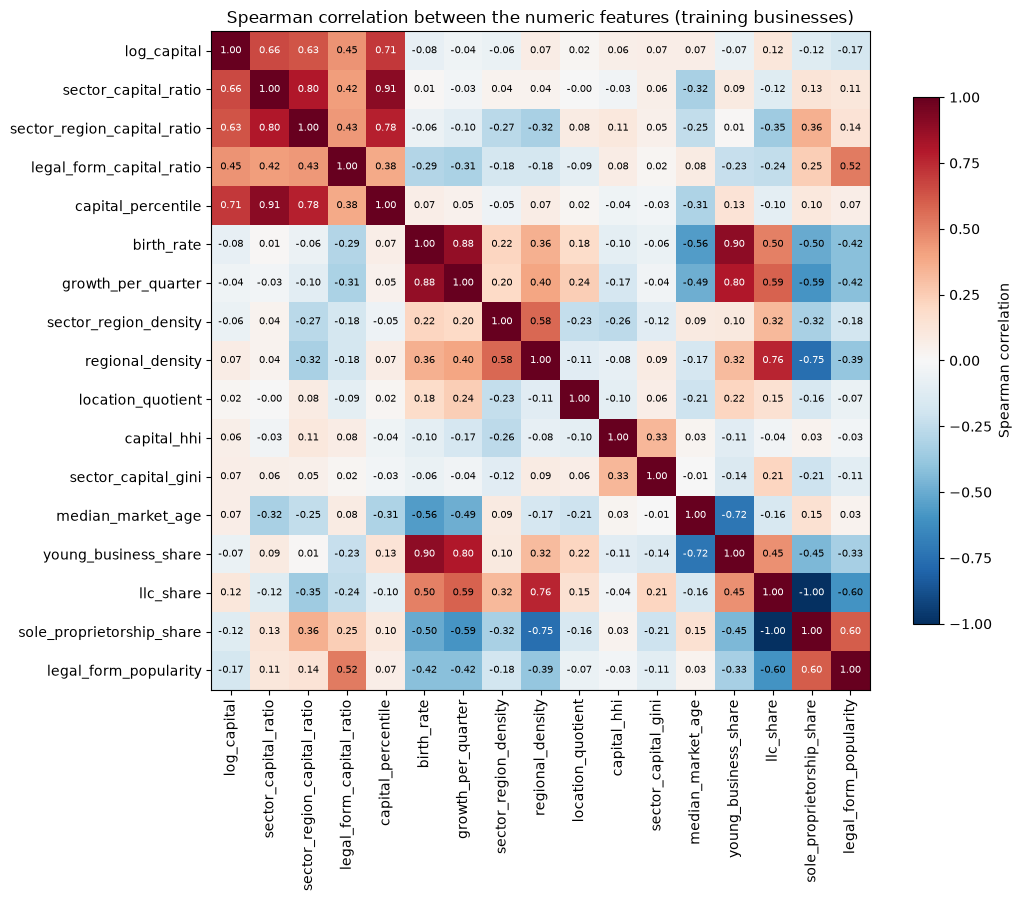

Pairs with an absolute correlation of at least 0.7: 11
                  feature 1                   feature 2  spearman
                  llc_share   sole_proprietorship_share     -1.00
       sector_capital_ratio          capital_percentile      0.91
                 birth_rate        young_business_share      0.90
                 birth_rate          growth_per_quarter      0.88
       sector_capital_ratio sector_region_capital_ratio      0.80
         growth_per_quarter        young_business_share      0.80
sector_region_capital_ratio          capital_percentile      0.78
           regional_density                   llc_share      0.76
           regional_density   sole_proprietorship_share     -0.75
          median_market_age        young_business_share     -0.72
                log_capital          capital_percentile      0.71


In [14]:
spearman = features[NUMERIC].corr(method='spearman')
figure, axis = plt.subplots(figsize=(11, 9))
image = axis.imshow(spearman, cmap='RdBu_r', vmin=-1, vmax=1)
axis.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=90)
axis.set_yticks(range(len(NUMERIC)), NUMERIC)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        axis.text(j, i, f'{spearman.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                  color='white' if abs(spearman.iloc[i, j]) > 0.6 else 'black')
figure.colorbar(image, ax=axis, shrink=0.8, label='Spearman correlation')
axis.set_title('Spearman correlation between the numeric features (training businesses)')
plt.tight_layout()
plt.show()

pairs = (spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1)).stack()
         .rename('spearman').reset_index().rename(columns={'level_0': 'feature 1', 'level_1': 'feature 2'}))
strong = pairs[pairs['spearman'].abs() >= 0.7].sort_values('spearman', key=abs, ascending=False)
print(f'Pairs with an absolute correlation of at least 0.7: {len(strong)}')
print(strong.to_string(index=False, float_format='{:.2f}'.format))

**Result.** Eleven pairs of numeric features have an absolute correlation of at least 0.7. The share of limited
liability companies and the share of sole proprietorships are exact opposites (−1.00). Birth rate is strongly
correlated with the share of young businesses (0.90) and with growth (0.88). The sector capital ratio is strongly
correlated with the capital percentile (0.91) and with the sector and region capital ratio (0.80). Regional
density is correlated with the legal form shares (0.76 and −0.75).

**Interpretation.** Several features repeat the same information, and only one of each group should be kept: one
of the two legal form shares; one of birth rate, growth and the share of young businesses; and one of the
capital ratios and the percentile.

In [15]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


cramer = pd.DataFrame(index=CATEGORICAL, columns=CATEGORICAL, dtype=float)
for a in CATEGORICAL:
    for b in CATEGORICAL:
        cramer.loc[a, b] = 1.0 if a == b else cramers_v(features[a], features[b])
print("Cramér's V between the categorical features (training businesses):")
print(cramer.to_string(float_format='{:.2f}'.format))

spearman.to_csv(REPORTS / '05_feature_correlation.csv', encoding='utf-8-sig')
cramer.to_csv(REPORTS / '05_categorical_association.csv', encoding='utf-8-sig')
profile.join(ranges).to_csv(REPORTS / '05_feature_profile.csv', encoding='utf-8-sig')
bins.to_csv(REPORTS / '05_feature_groups.csv', index=False, encoding='utf-8-sig')
print(f'\nSaved the correlation, association, profile and group tables (no business records) to {REPORTS}')

Cramér's V between the categorical features (training businesses):
                          economic_sector  region  city_group  legal_form  ecommerce  founding_quarter_of_year
economic_sector                      1.00    0.08        0.09        0.12       0.12                      0.04
region                               0.08    1.00        0.93        0.13       0.04                      0.04
city_group                           0.09    0.93        1.00        0.17       0.06                      0.06
legal_form                           0.12    0.13        0.17        1.00       0.05                      0.07
ecommerce                            0.12    0.04        0.06        0.05       1.00                      0.03
founding_quarter_of_year             0.04    0.04        0.06        0.07       0.03                      1.00

Saved the correlation, association, profile and group tables (no business records) to /Users/halaalsabbar/Darb/2026-GP1-G17/ml/reports


**Result.** Region and city group are almost interchangeable (Cramér's V 0.93). All other pairs of categorical
features are weakly related (0.17 or less).

**Interpretation.** Region and city should not both enter a logistic regression; one of them is enough. The
other categorical features carry distinct information.

## 10. Limitations

1. The capital of a business is its first recorded capital, and the market statistics describe the capital
   recorded for the active businesses, not their capital at the reference record.
2. Market statistics by sector rely on the sector inferred from business names; the businesses without a sector
   (about a quarter of the training businesses) are described at region level only.
3. Businesses founded in 2023 Q1 have no earlier record, so their market features are missing.
4. The reference record can be up to three quarters before the founding quarter, because the incomplete records
   are not used.
5. Births count only the businesses still present at the end of their founding quarter; businesses founded and
   closed within the same quarter are not seen.
6. The training labels of the latest training quarters are known only at their survival check (up to 2025 Q4),
   after the validation businesses were founded.
7. The keywords that infer the sector were counted partly from businesses founded after 2025 Q3 (Notebook 02,
   section 7.2); they do not use the survival outcome.
8. The relations shown are those of each feature alone, on the training businesses; the value of a feature
   within a model is measured only by comparing models on the validation businesses.

## 11. Summary of Findings

1. The training set holds 581,351 businesses founded from 2023 Q1 to 2024 Q4, with a failure rate of 17.3%
   (from 10.2% to 27.3% by founding quarter). The validation and test businesses were not examined.
2. 20,769 training businesses (3.6%) appear for the first time after their survival check quarter. All are
   labelled failed, and their characteristics are recorded after the outcome. Their treatment is an open
   question for Notebook 02.
3. The e-commerce value `unavailable` marks the businesses first recorded from 2025 Q4 (failure rate 87.2%) and
   must not enter a model in this form.
4. Businesses without a sector fail somewhat more often (+4.3 points), in every quarter and within each main
   legal form; they are kept as their own category.
5. Among the business-level features, legal form shows the largest difference (21.1% for sole proprietorships
   against 8.2% for limited liability companies). Most businesses register 5,000 SAR, so capital distinguishes
   few businesses.
6. Region and city are almost interchangeable (Cramér's V 0.93).
7. Alone, every market feature is weakly related to failure (area under the ROC curve from 0.503 to 0.601); none
   shows a sign of leakage.
8. Businesses entering larger, growing markets with many new businesses fail less often; part of this relation
   may reflect differences between founding quarters.
9. Location quotient, market age, capital concentration and capital relative to the sector show little or no
   relation to failure.
10. Several market features repeat each other (absolute correlation of at least 0.7 for eleven pairs); one
    feature of each group is enough.

**Decision required.** Which of these features enter the survival model in Release 1, and which are kept for
GP2. Their value within a model is measured by comparing models on the validation businesses, never on the test
businesses.